# Point Transformer V2 Model Evaluation

This notebook evaluates the trained model on the test set with detailed 3D visualizations.

**Focus Areas:**
- Power line detection accuracy
- Pylon detection accuracy
- Vegetation segmentation
- Per-class IoU metrics
- 3D visualizations highlighting power lines

**Classes:**
- Class 0: High Vegetation (Green)
- Class 1: Power Lines (Orange) ⚡
- Class 2: Pylons (Blue) 🗼
- Class 3: Others (Gray)

## 1. Setup and Imports

In [13]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import json
from tqdm import tqdm
# import pandas as pd
import seaborn as sns

# Set style
plt.style.use('default')
sns.set_palette('husl')

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"MPS available: {torch.backends.mps.is_available()}")

PyTorch version: 2.7.1
CUDA available: False
MPS available: True


## 2. Load Dataset Class

In [14]:
class PowerLineDataset(Dataset):
    """Dataset for power line point cloud segmentation"""

    def __init__(self, data_dir, split='test', num_points=4096, max_samples=None):
        self.data_dir = Path(data_dir) / split
        self.num_points = num_points
        self.split = split
        self.max_samples = max_samples

        # Get all sample files
        self.samples = sorted(list(self.data_dir.glob('*.pt')))
        
        # Limit to max_samples if specified
        if self.max_samples is not None:
            self.samples = self.samples[:self.max_samples]

        if not self.samples:
            raise ValueError(f"No samples found in {self.data_dir}")

        print(f"Loaded {len(self.samples)} samples from {split} split")

        # Load metadata
        metadata_path = Path(data_dir) / 'metadata.json'
        if metadata_path.exists():
            with open(metadata_path) as f:
                self.metadata = json.load(f)

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        sample = torch.load(self.samples[idx], weights_only=False)
        points = sample['input_pcd']
        labels = sample['semantic_labels']
        
        # Ensure labels is always 1D - flatten but keep at least 1 dimension
        labels = labels.reshape(-1)
        
        # Convert to 0-indexed
        labels = labels - 1
        
        # Ensure correct size
        n_points = points.shape[0]
        if n_points > self.num_points:
            choice = np.random.choice(n_points, self.num_points, replace=False)
            points = points[choice]
            labels = labels[choice]
        elif n_points < self.num_points:
            choice = np.random.choice(n_points, self.num_points - n_points, replace=True)
            extra_points = points[choice]
            extra_labels = labels[choice]
            points = torch.cat([points, extra_points], dim=0)
            labels = torch.cat([labels, extra_labels], dim=0)

        return {
            'points': points,
            'labels': labels,
            'idx': idx,
            'filename': self.samples[idx].name
        }

print("Dataset class loaded!")

Dataset class loaded!


## 3. Load Model Architecture

In [15]:
def knn(x, k):
    """Find k nearest neighbors"""
    inner = -2 * torch.matmul(x.transpose(2, 1), x)
    xx = torch.sum(x**2, dim=1, keepdim=True)
    pairwise_distance = -xx - inner - xx.transpose(2, 1)
    idx = pairwise_distance.topk(k=k, dim=-1)[1]
    return idx


class TransformerBlock(nn.Module):
    """Point Transformer Block"""
    def __init__(self, d_model, num_heads=8, k=16):
        super().__init__()
        self.d_model = d_model
        self.k = k
        self.q = nn.Linear(d_model, d_model)
        self.k_linear = nn.Linear(d_model, d_model)
        self.v = nn.Linear(d_model, d_model)
        self.pos_mlp = nn.Sequential(nn.Linear(3, d_model), nn.ReLU(), nn.Linear(d_model, d_model))
        self.ffn = nn.Sequential(nn.Linear(d_model, d_model * 4), nn.ReLU(), nn.Linear(d_model * 4, d_model))
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, features, positions, k=None):
        if k is None:
            k = self.k
        
        B, N, C = features.shape
        
        # KNN
        idx = knn(positions.transpose(1, 2), k)  # (B, N, k)
        
        # Gather neighbor features - use a safer indexing method
        idx_base = torch.arange(0, B, device=features.device).view(-1, 1, 1) * N
        idx_expanded = (idx + idx_base).view(B * N * k)
        
        features_flat = features.view(B * N, C)
        neighbor_features = features_flat[idx_expanded].view(B, N, k, C)
        
        positions_flat = positions.view(B * N, 3)
        neighbor_positions = positions_flat[idx_expanded].view(B, N, k, 3)
        
        # Relative positions
        relative_pos = positions.unsqueeze(2) - neighbor_positions
        pos_encoding = self.pos_mlp(relative_pos)
        
        # Attention
        q = self.q(features).unsqueeze(2)  # (B, N, 1, C)
        k_feat = self.k_linear(neighbor_features) + pos_encoding  # (B, N, k, C)
        v = self.v(neighbor_features) + pos_encoding  # (B, N, k, C)
        
        attn = torch.matmul(q, k_feat.transpose(-2, -1)) / (C ** 0.5)  # (B, N, 1, k)
        attn = F.softmax(attn, dim=-1)
        out = torch.matmul(attn, v).squeeze(2)  # (B, N, C)
        
        # Residual connections
        features = self.norm1(features + out)
        out = self.ffn(features)
        features = self.norm2(features + out)
        return features


class PointTransformerV2(nn.Module):
    """Point Transformer V2 for semantic segmentation"""
    def __init__(self, num_classes=4, d_model=128, num_layers=2, k=16):
        super().__init__()
        self.num_classes = num_classes
        self.input_embed = nn.Sequential(
            nn.Linear(3, 64),
            nn.ReLU(),
            nn.Linear(64, d_model)
        )
        self.blocks = nn.ModuleList([
            TransformerBlock(d_model, k=k) for _ in range(num_layers)
        ])
        self.seg_head = nn.Sequential(
            nn.Linear(d_model, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, points):
        features = self.input_embed(points)
        for block in self.blocks:
            features = block(features, points)
        logits = self.seg_head(features)
        return logits

print("Model architecture loaded!")

Model architecture loaded!


## 4. Configuration and Setup

In [16]:
# Configuration
CONFIG = {
    'data_dir': '../data/processed_data_optimized',
    'checkpoint_path': 'checkpoints/pointtransformer-epoch=04-val_miou=0.421.ckpt',  # Path to your trained model
    'batch_size': 4,
    'num_points': 4096,
    'output_dir': 'evaluation_results',
    'num_vis_samples': 10  # Number of samples to visualize
}

# Create output directory
Path(CONFIG['output_dir']).mkdir(exist_ok=True)

# Class information
CLASS_NAMES = ['High Vegetation', 'Power Lines', 'Pylons', 'Others']
CLASS_COLORS = ['darkgreen', 'orange', 'blue', 'gray']
CLASS_COLORS_RGB = [
    [0, 100, 0],      # Dark green for vegetation
    [255, 140, 0],    # Orange for power lines
    [0, 0, 255],      # Blue for pylons
    [128, 128, 128]   # Gray for others
]

# Device setup
if torch.cuda.is_available():
    device = 'cuda'
    print("Using CUDA GPU")
elif torch.backends.mps.is_available():
    device = 'mps'
    print("Using Apple Silicon MPS")
else:
    device = 'cpu'
    print("Using CPU")

print(f"\nConfiguration:")
for key, value in CONFIG.items():
    print(f"  {key}: {value}")

Using Apple Silicon MPS

Configuration:
  data_dir: ../data/processed_data_optimized
  checkpoint_path: checkpoints/pointtransformer-epoch=04-val_miou=0.421.ckpt
  batch_size: 4
  num_points: 4096
  output_dir: evaluation_results
  num_vis_samples: 10


## 5. Load Trained Model

In [17]:
# Load model from checkpoint
checkpoint_path = Path(CONFIG['checkpoint_path'])

if not checkpoint_path.exists():
    raise FileNotFoundError(f"Checkpoint not found at {checkpoint_path}")

print(f"Loading model from {checkpoint_path}...")

# Load checkpoint
checkpoint = torch.load(checkpoint_path, map_location=device)

# Extract hyperparameters
hparams = checkpoint['hyper_parameters']
print(f"Model hyperparameters:")
print(f"  num_classes: {hparams['num_classes']}")
print(f"  d_model: {hparams['d_model']}")
print(f"  num_layers: {hparams['num_layers']}")

# Get k parameter if it exists, otherwise default to 16
k_neighbors = hparams.get('k', 16)
print(f"  k_neighbors: {k_neighbors}")

# Create model
model = PointTransformerV2(
    num_classes=hparams['num_classes'],
    d_model=hparams['d_model'],
    num_layers=hparams['num_layers'],
    k=k_neighbors
)

# Load state dict
state_dict = {k.replace('model.', ''): v for k, v in checkpoint['state_dict'].items() if k.startswith('model.')}
model.load_state_dict(state_dict)

model = model.to(device)
model.eval()

print(f"\nModel loaded successfully!")
print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")

Loading model from checkpoints/pointtransformer-epoch=04-val_miou=0.421.ckpt...
Model hyperparameters:
  num_classes: 4
  d_model: 128
  num_layers: 2
  k_neighbors: 16

Model loaded successfully!
Total parameters: 472,580


## 6. Load Test Dataset

In [18]:
# Load test dataset
test_dataset = PowerLineDataset(
    CONFIG['data_dir'],
    split='test',
    num_points=CONFIG['num_points'],
    max_samples=None  # Use all test samples
)

test_loader = DataLoader(
    test_dataset,
    batch_size=CONFIG['batch_size'],
    shuffle=False,
    num_workers=0
)

print(f"Test dataset: {len(test_dataset)} samples")
print(f"Test batches: {len(test_loader)}")

Loaded 6203 samples from test split
Test dataset: 6203 samples
Test batches: 1551


## 7. Evaluate Model on Test Set

In [19]:
def calculate_metrics(pred, target, num_classes=4):
    """Calculate per-class IoU and accuracy"""
    pred = pred.view(-1).cpu().numpy()
    target = target.view(-1).cpu().numpy()
    
    metrics = {
        'iou': [],
        'precision': [],
        'recall': [],
        'f1': [],
        'count': []
    }
    
    for cls in range(num_classes):
        pred_mask = pred == cls
        target_mask = target == cls
        
        tp = np.sum(pred_mask & target_mask)
        fp = np.sum(pred_mask & ~target_mask)
        fn = np.sum(~pred_mask & target_mask)
        
        # IoU
        union = tp + fp + fn
        iou = tp / union if union > 0 else 0
        
        # Precision, Recall, F1
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
        
        metrics['iou'].append(iou)
        metrics['precision'].append(precision)
        metrics['recall'].append(recall)
        metrics['f1'].append(f1)
        metrics['count'].append(np.sum(target_mask))
    
    return metrics


print("Evaluating model on test set...")
all_metrics = {
    'iou': np.zeros(4),
    'precision': np.zeros(4),
    'recall': np.zeros(4),
    'f1': np.zeros(4),
    'count': np.zeros(4)
}

all_predictions = []
all_labels = []

with torch.no_grad():
    for batch in tqdm(test_loader, desc="Evaluating"):
        points = batch['points'].to(device)
        labels = batch['labels'].to(device)
        
        # Forward pass
        logits = model(points)
        pred = logits.argmax(dim=-1)
        
        # Calculate metrics
        metrics = calculate_metrics(pred, labels)
        
        for key in all_metrics:
            all_metrics[key] += np.array(metrics[key])
        
        all_predictions.append(pred.cpu())
        all_labels.append(labels.cpu())

# Average metrics
num_batches = len(test_loader)
for key in ['iou', 'precision', 'recall', 'f1']:
    all_metrics[key] /= num_batches

print("\nEvaluation complete!")

Evaluating model on test set...


Evaluating: 100%|██████████| 1551/1551 [20:25<00:00,  1.27it/s]


Evaluation complete!


## 8. Display Evaluation Results

In [21]:
import pandas as pd
# Create results dataframe
results_df = pd.DataFrame({
    'Class': CLASS_NAMES,
    'IoU': all_metrics['iou'],
    'Precision': all_metrics['precision'],
    'Recall': all_metrics['recall'],
    'F1-Score': all_metrics['f1'],
    'Point Count': all_metrics['count'].astype(int)
})

print("\n" + "="*80)
print("EVALUATION RESULTS")
print("="*80)
print(results_df.to_string(index=False))
print("="*80)

# Calculate mean metrics
print(f"\nMean IoU: {all_metrics['iou'].mean():.4f}")
print(f"Mean Precision: {all_metrics['precision'].mean():.4f}")
print(f"Mean Recall: {all_metrics['recall'].mean():.4f}")
print(f"Mean F1-Score: {all_metrics['f1'].mean():.4f}")

# Highlight power line and pylon performance
print(f"\n" + "="*80)
print("CRITICAL CLASSES (Power Lines & Pylons)")
print("="*80)
print(f"Power Lines - IoU: {all_metrics['iou'][1]:.4f}, F1: {all_metrics['f1'][1]:.4f}")
print(f"Pylons      - IoU: {all_metrics['iou'][2]:.4f}, F1: {all_metrics['f1'][2]:.4f}")

# Save results
results_df.to_csv(f"{CONFIG['output_dir']}/evaluation_metrics.csv", index=False)
print(f"\nResults saved to {CONFIG['output_dir']}/evaluation_metrics.csv")


EVALUATION RESULTS
          Class      IoU  Precision   Recall  F1-Score  Point Count
High Vegetation 0.555770   0.722652 0.743942  0.661208     15028573
    Power Lines 0.085497   0.108687 0.101266  0.098156        46220
         Pylons 0.000000   0.000000 0.000000  0.000000         2509
         Others 0.346926   0.594471 0.484406  0.434984     10330186

Mean IoU: 0.2470
Mean Precision: 0.3565
Mean Recall: 0.3324
Mean F1-Score: 0.2986

CRITICAL CLASSES (Power Lines & Pylons)
Power Lines - IoU: 0.0855, F1: 0.0982
Pylons      - IoU: 0.0000, F1: 0.0000

Results saved to evaluation_results/evaluation_metrics.csv


## 9. Visualize Metrics

/var/folders/ps/w_1s3b6515181dg8hd57mkd80000gn/T/ipykernel_99070/234318658.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(CLASS_NAMES, rotation=45, ha='right')
/var/folders/ps/w_1s3b6515181dg8hd57mkd80000gn/T/ipykernel_99070/234318658.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(CLASS_NAMES, rotation=45, ha='right')
/var/folders/ps/w_1s3b6515181dg8hd57mkd80000gn/T/ipykernel_99070/234318658.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(CLASS_NAMES, rotation=45, ha='right')
/var/folders/ps/w_1s3b6515181dg8hd57mkd80000gn/T/ipykernel_99070/234318658.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using

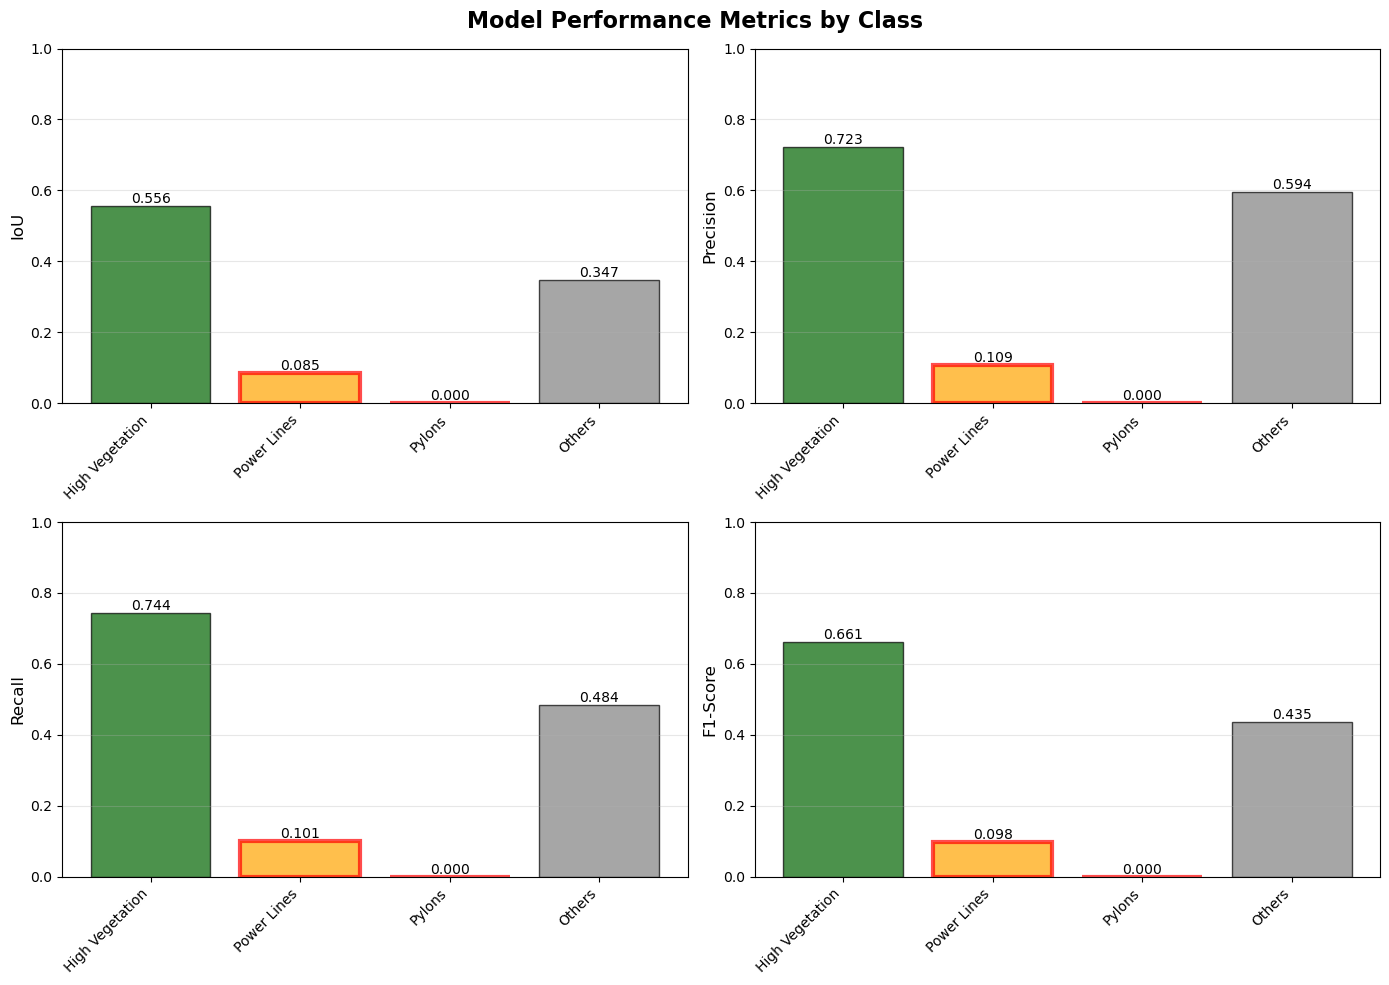

Metrics plot saved to evaluation_results/metrics_comparison.png


In [22]:
# Plot metrics
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Model Performance Metrics by Class', fontsize=16, fontweight='bold')

metrics_to_plot = ['IoU', 'Precision', 'Recall', 'F1-Score']
for idx, metric in enumerate(metrics_to_plot):
    ax = axes[idx // 2, idx % 2]
    bars = ax.bar(CLASS_NAMES, results_df[metric], color=CLASS_COLORS, alpha=0.7, edgecolor='black')
    
    # Highlight power lines and pylons
    bars[1].set_edgecolor('red')
    bars[1].set_linewidth(3)
    bars[2].set_edgecolor('red')
    bars[2].set_linewidth(3)
    
    ax.set_ylabel(metric, fontsize=12)
    ax.set_ylim(0, 1)
    ax.grid(axis='y', alpha=0.3)
    ax.set_xticklabels(CLASS_NAMES, rotation=45, ha='right')
    
    # Add value labels on bars
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.3f}',
                ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig(f"{CONFIG['output_dir']}/metrics_comparison.png", dpi=300, bbox_inches='tight')
plt.show()

print(f"Metrics plot saved to {CONFIG['output_dir']}/metrics_comparison.png")

## 10. 3D Visualization Function

In [23]:
def visualize_3d_prediction(points, labels, predictions, sample_idx, save_path=None):
    """
    Create 3D visualization with emphasis on power lines
    """
    points_np = points.cpu().numpy()
    labels_np = labels.cpu().numpy()
    pred_np = predictions.cpu().numpy()
    
    fig = plt.figure(figsize=(20, 8))
    fig.suptitle(f'Sample {sample_idx}: 3D Point Cloud Segmentation', fontsize=16, fontweight='bold')
    
    # Ground Truth
    ax1 = fig.add_subplot(131, projection='3d')
    ax1.set_title('Ground Truth', fontsize=14, fontweight='bold')
    for cls in range(4):
        mask = labels_np == cls
        if mask.sum() > 0:
            size = 20 if cls in [1, 2] else 1  # Larger points for power lines and pylons
            ax1.scatter(points_np[mask, 0], points_np[mask, 1], points_np[mask, 2],
                       c=CLASS_COLORS[cls], label=CLASS_NAMES[cls], s=size, alpha=0.8)
    ax1.legend(loc='upper right')
    ax1.set_xlabel('X')
    ax1.set_ylabel('Y')
    ax1.set_zlabel('Z')
    
    # Prediction
    ax2 = fig.add_subplot(132, projection='3d')
    ax2.set_title('Model Prediction', fontsize=14, fontweight='bold')
    for cls in range(4):
        mask = pred_np == cls
        if mask.sum() > 0:
            size = 20 if cls in [1, 2] else 1
            ax2.scatter(points_np[mask, 0], points_np[mask, 1], points_np[mask, 2],
                       c=CLASS_COLORS[cls], label=CLASS_NAMES[cls], s=size, alpha=0.8)
    ax2.legend(loc='upper right')
    ax2.set_xlabel('X')
    ax2.set_ylabel('Y')
    ax2.set_zlabel('Z')
    
    # Power Lines Focus View
    ax3 = fig.add_subplot(133, projection='3d')
    ax3.set_title('Power Lines & Pylons Focus', fontsize=14, fontweight='bold')
    
    # Show only power lines and pylons with surrounding context
    powerline_mask_gt = labels_np == 1
    pylon_mask_gt = labels_np == 2
    powerline_mask_pred = pred_np == 1
    pylon_mask_pred = pred_np == 2
    
    # Ground truth power infrastructure
    if powerline_mask_gt.sum() > 0:
        ax3.scatter(points_np[powerline_mask_gt, 0], points_np[powerline_mask_gt, 1], 
                   points_np[powerline_mask_gt, 2], c='orange', label='GT Power Lines', 
                   s=30, alpha=0.9, marker='o')
    if pylon_mask_gt.sum() > 0:
        ax3.scatter(points_np[pylon_mask_gt, 0], points_np[pylon_mask_gt, 1], 
                   points_np[pylon_mask_gt, 2], c='blue', label='GT Pylons', 
                   s=30, alpha=0.9, marker='^')
    
    # Predicted power infrastructure (different markers)
    if powerline_mask_pred.sum() > 0:
        ax3.scatter(points_np[powerline_mask_pred, 0], points_np[powerline_mask_pred, 1], 
                   points_np[powerline_mask_pred, 2], c='red', label='Pred Power Lines', 
                   s=15, alpha=0.6, marker='x')
    if pylon_mask_pred.sum() > 0:
        ax3.scatter(points_np[pylon_mask_pred, 0], points_np[pylon_mask_pred, 1], 
                   points_np[pylon_mask_pred, 2], c='cyan', label='Pred Pylons', 
                   s=15, alpha=0.6, marker='+')
    
    ax3.legend(loc='upper right')
    ax3.set_xlabel('X')
    ax3.set_ylabel('Y')
    ax3.set_zlabel('Z')
    
    # Calculate and display metrics for this sample
    sample_metrics = calculate_metrics(
        torch.from_numpy(pred_np), 
        torch.from_numpy(labels_np)
    )
    
    metrics_text = f"IoU - Veg: {sample_metrics['iou'][0]:.3f}, PL: {sample_metrics['iou'][1]:.3f}, Pylon: {sample_metrics['iou'][2]:.3f}, Other: {sample_metrics['iou'][3]:.3f}"
    fig.text(0.5, 0.02, metrics_text, ha='center', fontsize=11, bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    
    plt.show()
    
print("3D visualization function ready!")

3D visualization function ready!


## 11. Generate Visualizations for Test Samples

Generating 10 visualizations...

Found 10 samples with power lines/pylons


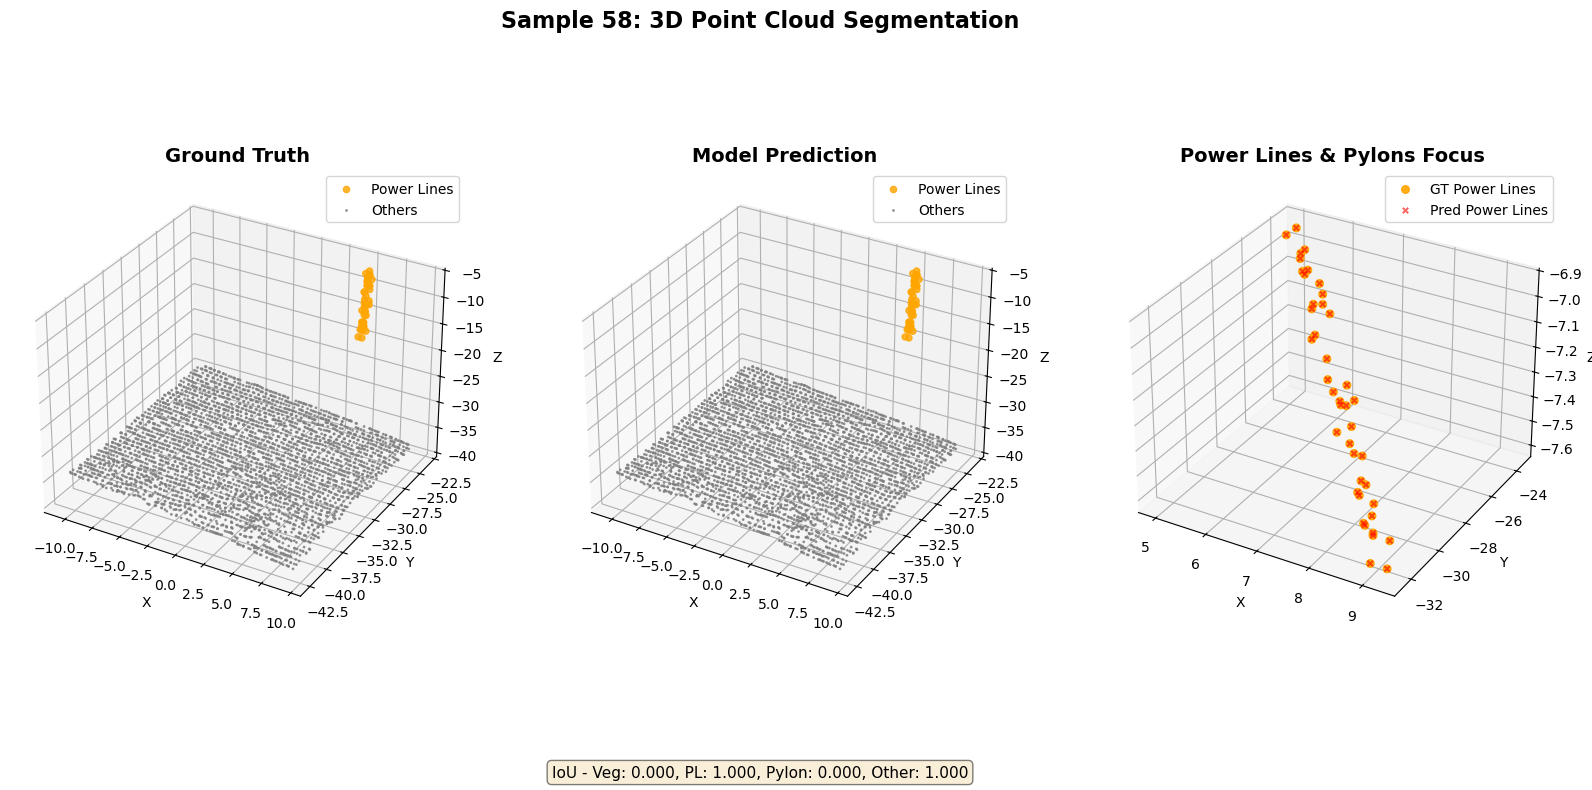

Saved visualization 1/10


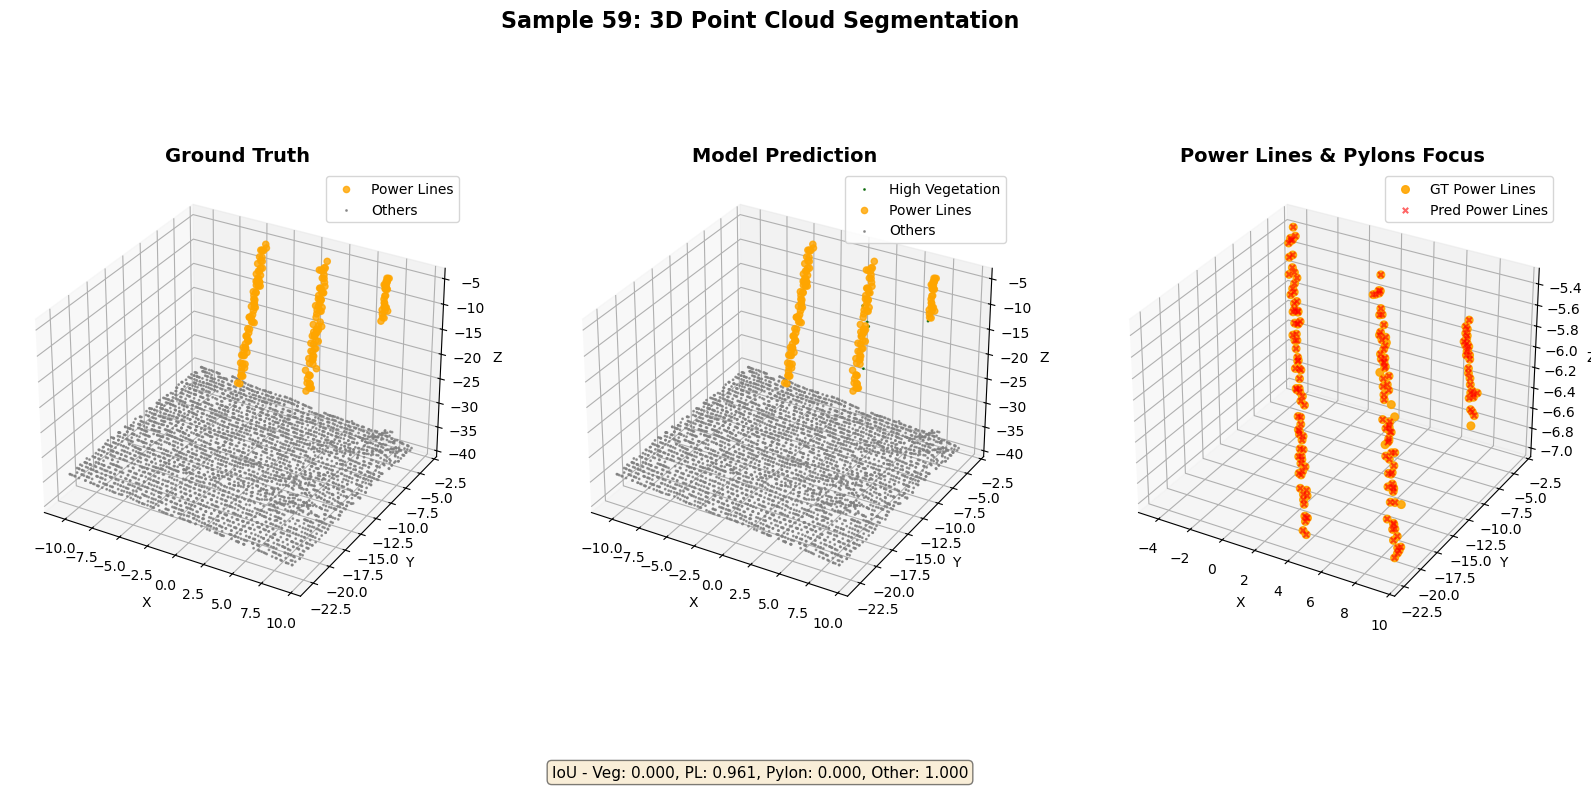

Saved visualization 2/10


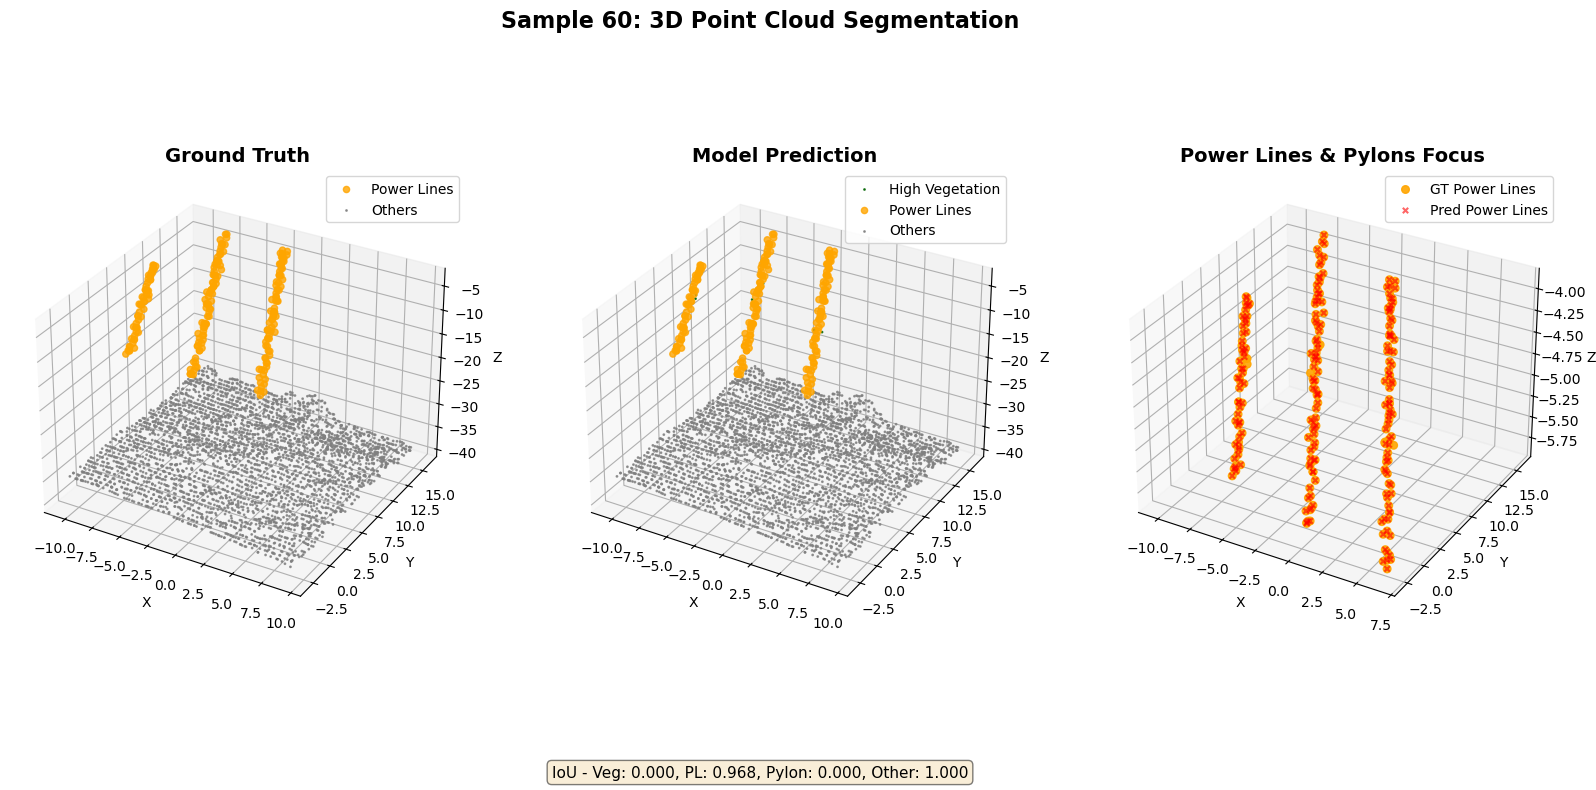

Saved visualization 3/10


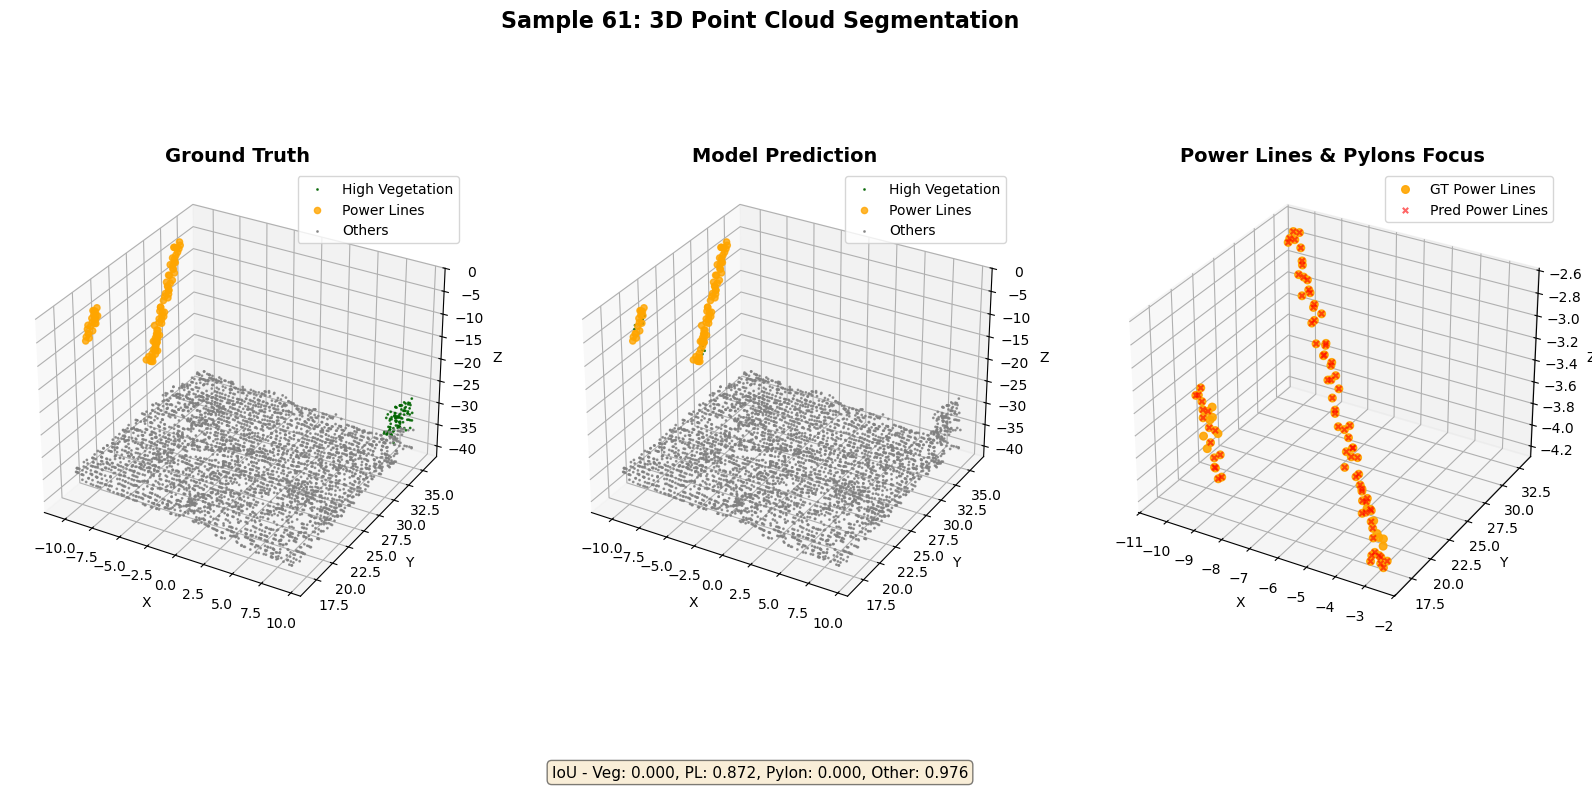

Saved visualization 4/10


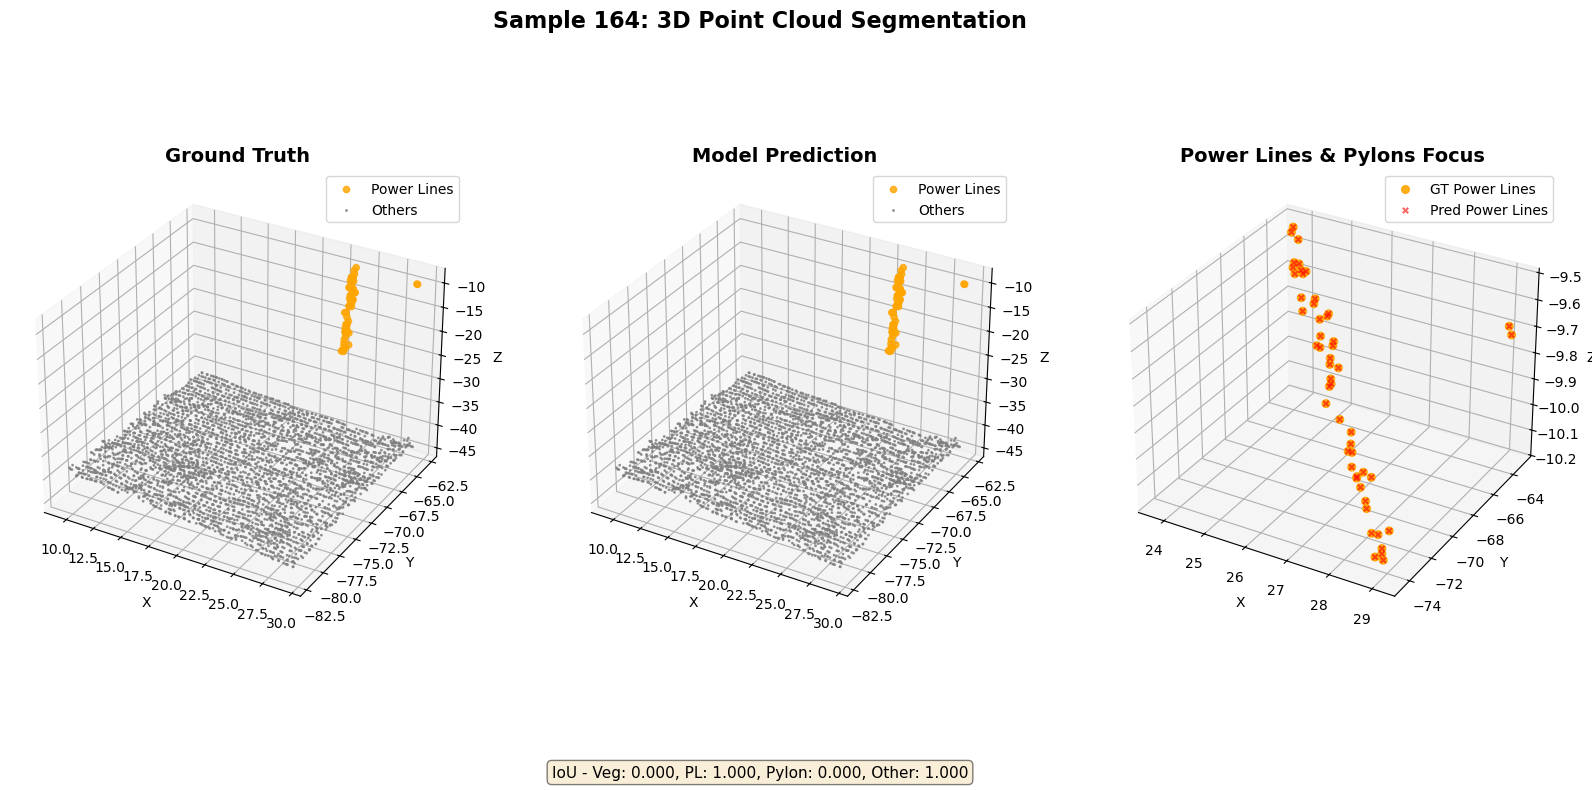

Saved visualization 5/10


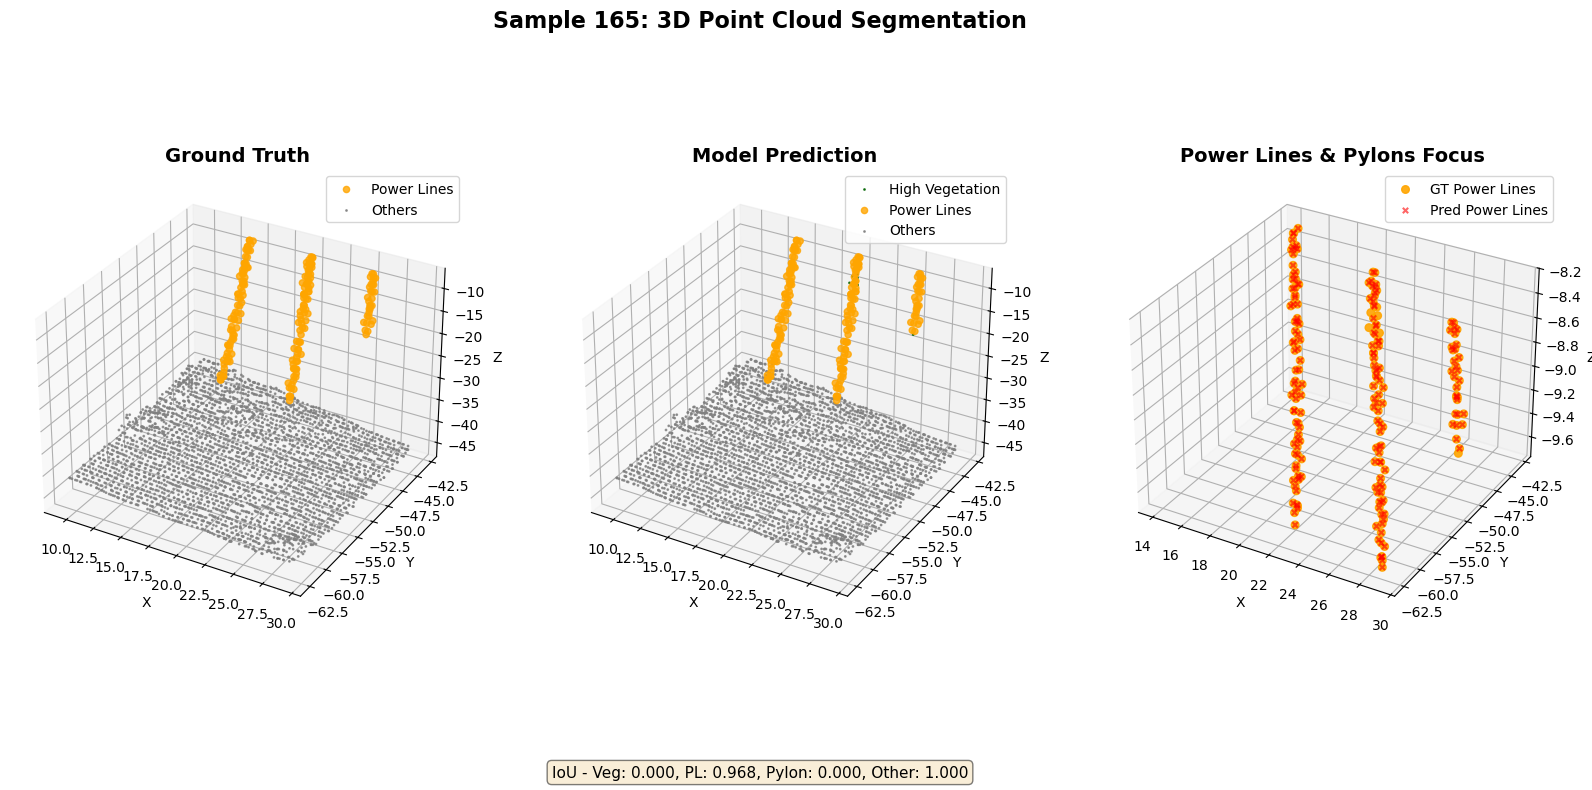

Saved visualization 6/10


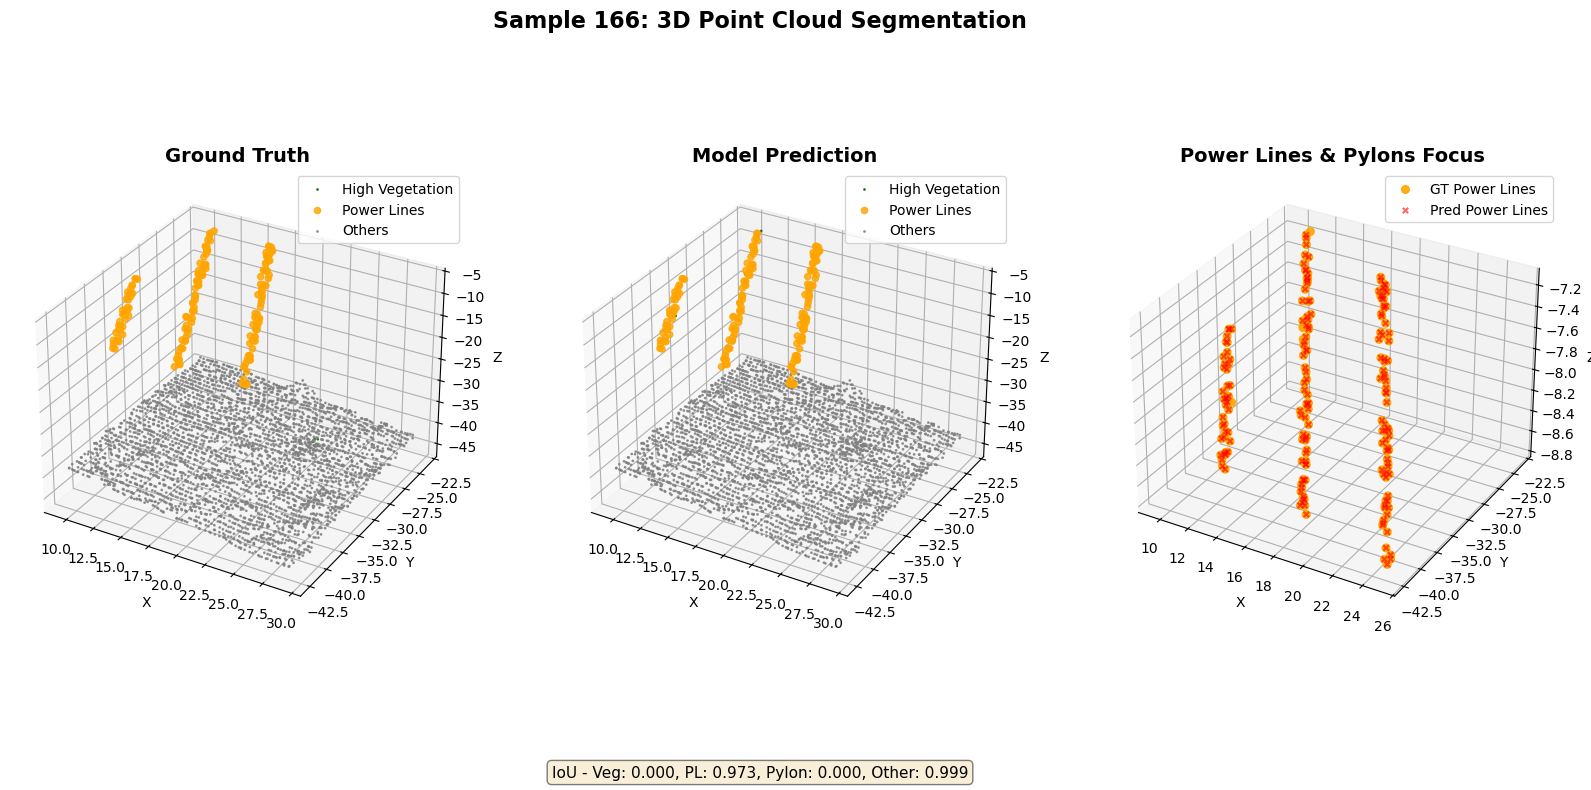

Saved visualization 7/10


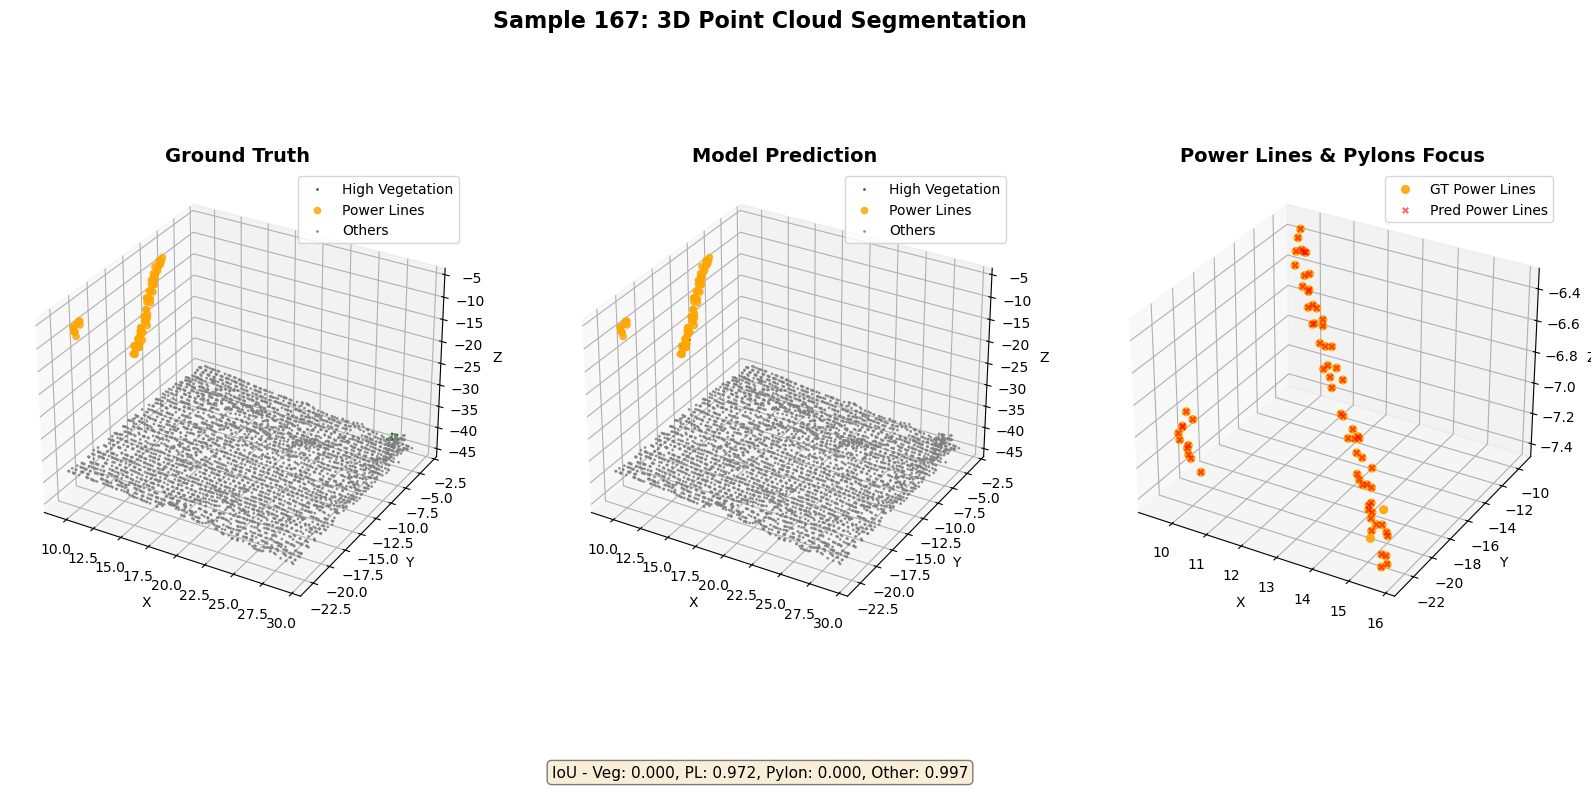

Saved visualization 8/10


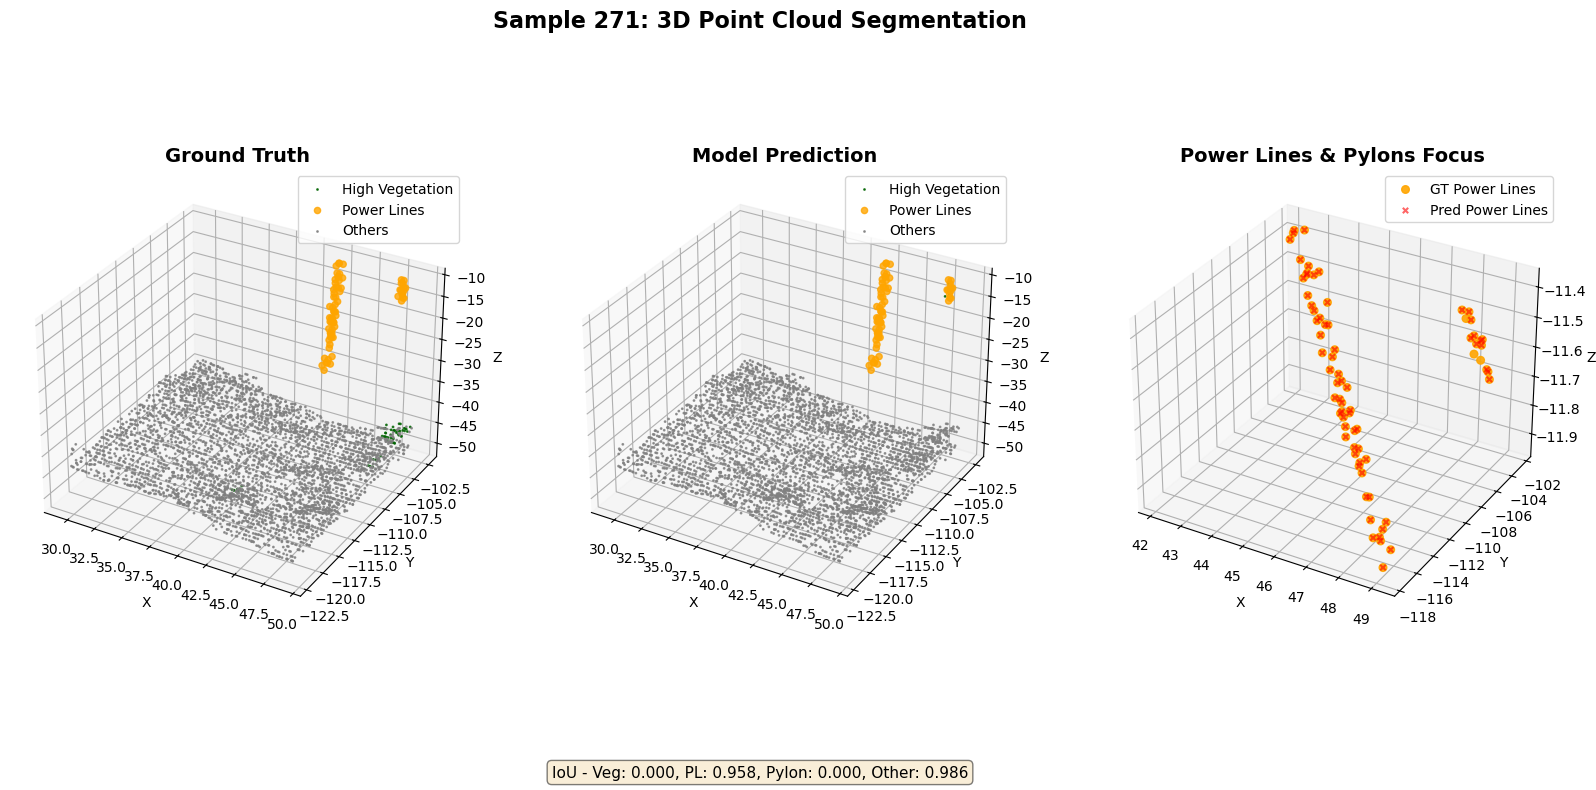

Saved visualization 9/10


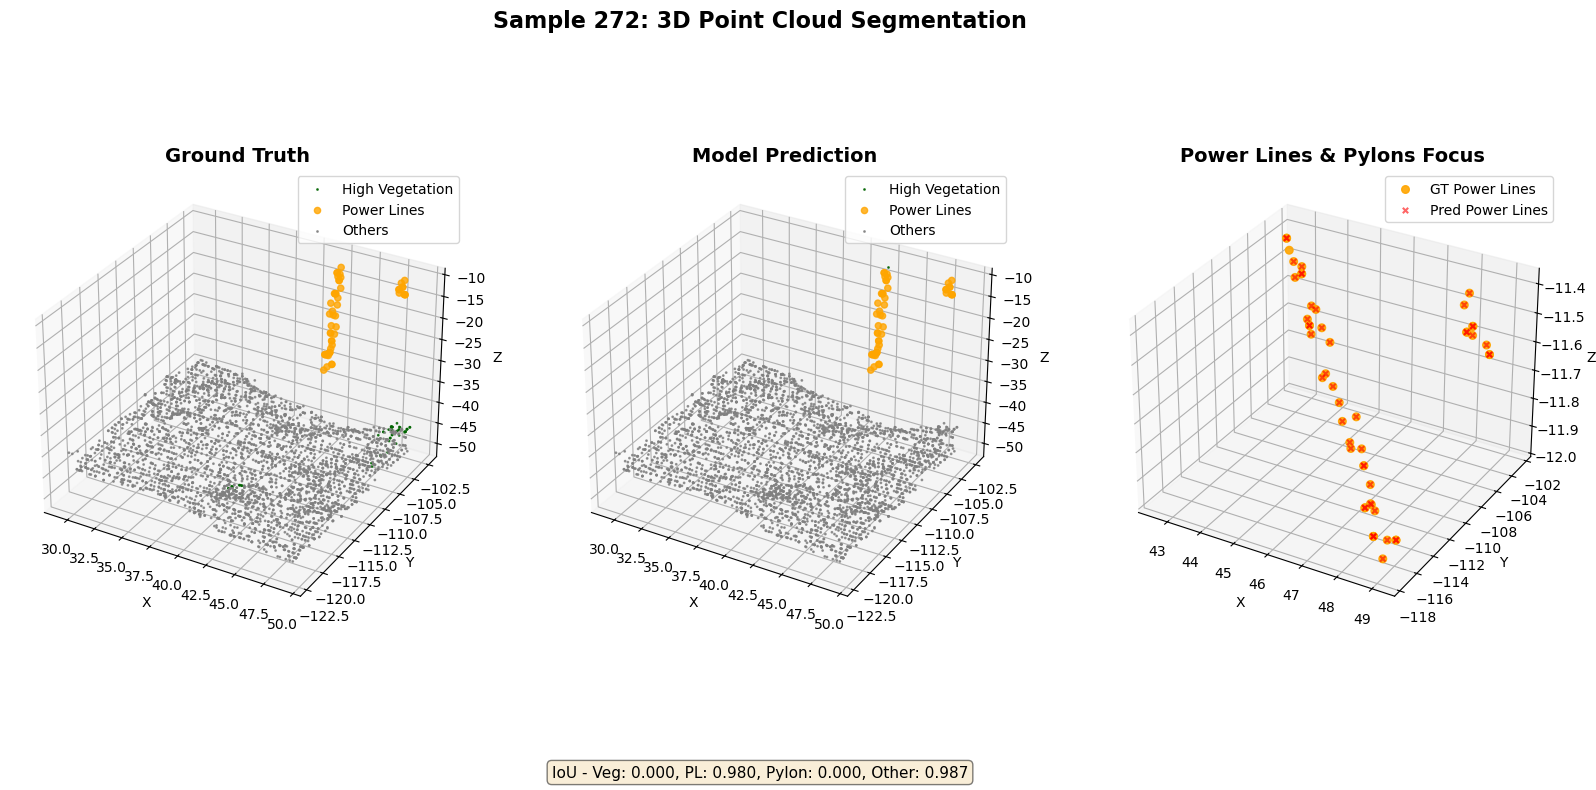

Saved visualization 10/10

All visualizations saved to evaluation_results/visualizations/


In [24]:
print(f"Generating {CONFIG['num_vis_samples']} visualizations...\n")

# Find samples with power lines or pylons
samples_with_powerlines = []
for idx in range(len(test_dataset)):
    sample = test_dataset[idx]
    labels = sample['labels']
    if ((labels == 1).sum() > 10 or (labels == 2).sum() > 5):  # Has power lines or pylons
        samples_with_powerlines.append(idx)
    if len(samples_with_powerlines) >= CONFIG['num_vis_samples']:
        break

print(f"Found {len(samples_with_powerlines)} samples with power lines/pylons")

# Generate visualizations
vis_dir = Path(CONFIG['output_dir']) / 'visualizations'
vis_dir.mkdir(exist_ok=True)

with torch.no_grad():
    for i, idx in enumerate(samples_with_powerlines[:CONFIG['num_vis_samples']]):
        sample = test_dataset[idx]
        points = sample['points'].unsqueeze(0).to(device)
        labels = sample['labels']
        
        # Predict
        logits = model(points)
        predictions = logits.argmax(dim=-1)[0]
        
        # Visualize
        save_path = vis_dir / f'sample_{idx:04d}.png'
        visualize_3d_prediction(points[0], labels, predictions, idx, save_path)
        print(f"Saved visualization {i+1}/{len(samples_with_powerlines[:CONFIG['num_vis_samples']])}")

print(f"\nAll visualizations saved to {vis_dir}/")

## 12. Confusion Matrix

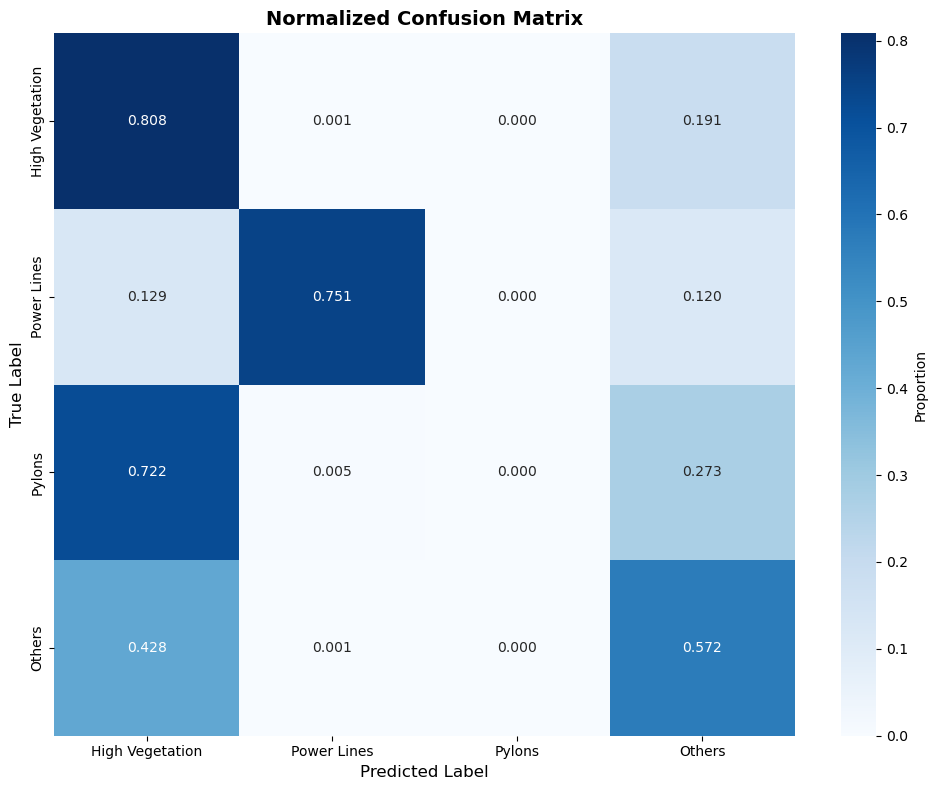

Confusion matrix saved to evaluation_results/confusion_matrix.png


In [25]:
from sklearn.metrics import confusion_matrix

# Concatenate all predictions and labels
all_pred = torch.cat(all_predictions).numpy().flatten()
all_true = torch.cat(all_labels).numpy().flatten()

# Calculate confusion matrix
cm = confusion_matrix(all_true, all_pred, labels=[0, 1, 2, 3])

# Normalize by row (true labels)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# Plot
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm_normalized, annot=True, fmt='.3f', cmap='Blues', 
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            cbar_kws={'label': 'Proportion'})
ax.set_xlabel('Predicted Label', fontsize=12)
ax.set_ylabel('True Label', fontsize=12)
ax.set_title('Normalized Confusion Matrix', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig(f"{CONFIG['output_dir']}/confusion_matrix.png", dpi=300, bbox_inches='tight')
plt.show()

print(f"Confusion matrix saved to {CONFIG['output_dir']}/confusion_matrix.png")

## 13. Summary Report

In [26]:
# Generate summary report
report = f"""
{'='*80}
POINT TRANSFORMER V2 - EVALUATION SUMMARY REPORT
{'='*80}

Model: Point Transformer V2
Checkpoint: {CONFIG['checkpoint_path']}
Test Samples: {len(test_dataset)}

{'='*80}
OVERALL PERFORMANCE
{'='*80}
Mean IoU:       {all_metrics['iou'].mean():.4f}
Mean Precision: {all_metrics['precision'].mean():.4f}
Mean Recall:    {all_metrics['recall'].mean():.4f}
Mean F1-Score:  {all_metrics['f1'].mean():.4f}

{'='*80}
PER-CLASS PERFORMANCE
{'='*80}
"""

for i, cls_name in enumerate(CLASS_NAMES):
    report += f"""
{cls_name}:
  IoU:       {all_metrics['iou'][i]:.4f}
  Precision: {all_metrics['precision'][i]:.4f}
  Recall:    {all_metrics['recall'][i]:.4f}
  F1-Score:  {all_metrics['f1'][i]:.4f}
  Points:    {int(all_metrics['count'][i]):,}
"""

report += f"""
{'='*80}
CRITICAL INFRASTRUCTURE DETECTION
{'='*80}
Power Lines:
  Detection Rate (Recall): {all_metrics['recall'][1]:.2%}
  Precision:               {all_metrics['precision'][1]:.2%}
  F1-Score:                {all_metrics['f1'][1]:.4f}

Pylons:
  Detection Rate (Recall): {all_metrics['recall'][2]:.2%}
  Precision:               {all_metrics['precision'][2]:.2%}
  F1-Score:                {all_metrics['f1'][2]:.4f}

{'='*80}
OUTPUT FILES
{'='*80}
- Metrics CSV: {CONFIG['output_dir']}/evaluation_metrics.csv
- Metrics Plot: {CONFIG['output_dir']}/metrics_comparison.png
- Confusion Matrix: {CONFIG['output_dir']}/confusion_matrix.png
- Visualizations: {CONFIG['output_dir']}/visualizations/
{'='*80}
"""

print(report)

# Save report
with open(f"{CONFIG['output_dir']}/evaluation_report.txt", 'w') as f:
    f.write(report)

print(f"\nReport saved to {CONFIG['output_dir']}/evaluation_report.txt")


POINT TRANSFORMER V2 - EVALUATION SUMMARY REPORT

Model: Point Transformer V2
Checkpoint: checkpoints/pointtransformer-epoch=04-val_miou=0.421.ckpt
Test Samples: 6203

OVERALL PERFORMANCE
Mean IoU:       0.2470
Mean Precision: 0.3565
Mean Recall:    0.3324
Mean F1-Score:  0.2986

PER-CLASS PERFORMANCE

High Vegetation:
  IoU:       0.5558
  Precision: 0.7227
  Recall:    0.7439
  F1-Score:  0.6612
  Points:    15,028,573

Power Lines:
  IoU:       0.0855
  Precision: 0.1087
  Recall:    0.1013
  F1-Score:  0.0982
  Points:    46,220

Pylons:
  IoU:       0.0000
  Precision: 0.0000
  Recall:    0.0000
  F1-Score:  0.0000
  Points:    2,509

Others:
  IoU:       0.3469
  Precision: 0.5945
  Recall:    0.4844
  F1-Score:  0.4350
  Points:    10,330,186

CRITICAL INFRASTRUCTURE DETECTION
Power Lines:
  Detection Rate (Recall): 10.13%
  Precision:               10.87%
  F1-Score:                0.0982

Pylons:
  Detection Rate (Recall): 0.00%
  Precision:               0.00%
  F1-Score:   

## Summary

This notebook has evaluated your trained Point Transformer V2 model with:

1. ✅ **Comprehensive metrics** - IoU, Precision, Recall, F1 for all classes
2. ✅ **3D visualizations** - Emphasis on power lines and pylons
3. ✅ **Confusion matrix** - Understanding misclassifications
4. ✅ **Detailed reports** - CSV and text summaries

**Key Focus:**
- Power line detection performance
- Pylon identification accuracy
- Visual comparison of predictions vs ground truth

All results are saved in the `evaluation_results/` directory.